# Tugas Mandiri 1 Information Retrieval: Perbandingan Cosine TF-IDF dan BM25

**Mata Kuliah:** Information Retrieval  
**Topik:** Model Probabilistik, BM25, dan Relevance Feedback (Pertemuan 5)  
**Nama:** Anisa Nur Azizah  
**NPM:** 24081010238  
**Korpus:** 50 Artikel Berita Berbahasa Indonesia (Antara News)

---
### Alur pengerjaan
1. **Siapkan korpus dan query**: muat korpus, praproses, lalu susun 14 query uji beserta dokumen yang saya anggap relevan.
2. **Terapkan dua model**: Cosine TF-IDF (skema ltc.ltc) dan BM25 dengan k1 = 1,2 serta b = 0,75, keduanya ditulis sendiri tanpa library IR.
3. **Uji pengaruh parameter**: BM25 diulang untuk beberapa nilai k1 dan b, lalu dicatat perubahan peringkatnya.
4. **Bandingkan dan analisis**: mencari query yang peringkatnya berbeda, lalu menelusuri penyebabnya lewat rincian rumus per term.
5. **Simpan hasil** untuk bahan laporan.

## 1. Instalasi & Import Library
Library yang dipakai sama dengan praktikum sebelumnya (PySastrawi, NLTK, pandas, matplotlib), ditambah `scipy` untuk menghitung korelasi peringkat Kendall tau. Kedua model (TF-IDF dan BM25) saya tulis sendiri dengan `dict`, `Counter`, dan `math`, jadi tidak memakai `TfidfVectorizer`, `rank_bm25`, atau sejenisnya.

In [1]:
!pip install PySastrawi nltk pandas matplotlib scipy -q

import os, re, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from typing import List, Set, Dict, Tuple
from scipy.stats import kendalltau
from IPython.display import display

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import nltk

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
print("Semua library berhasil diimpor!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 16.9 MB/s eta 0:00:00
Semua library berhasil diimpor!


## 2. Memuat Korpus Berita Indonesia (50 Artikel)
Korpusnya `berita_indonesia_50.csv` (kolom `id`, `judul`, `isi_berita`, `sumber`), sama dengan praktikum sebelumnya. Kolom `id` dipakai sebagai docID. Kalau file belum ada di Colab, kode akan meminta saya mengunggahnya.

In [2]:
CSV_FILE = "berita_indonesia_50.csv"

if not os.path.exists(CSV_FILE):
    try:
        from google.colab import files
        print(f"File '{CSV_FILE}' belum ditemukan. Silakan unggah file CSV korpus...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"File '{CSV_FILE}' tidak ditemukan.")

df = pd.read_csv(CSV_FILE)
df = df.dropna(subset=["isi_berita"]).reset_index(drop=True)
JUDUL = {int(r.id): r.judul for r in df.itertuples()}      # docID -> judul (untuk menampilkan hasil)
print(f"Berhasil memuat {len(df)} artikel dari '{CSV_FILE}'")
display(df.head(3)[["id", "judul", "sumber"]])

File 'berita_indonesia_50.csv' belum ditemukan. Silakan unggah file CSV korpus...


Saving berita_indonesia_50.csv to berita_indonesia_50.csv
Berhasil memuat 50 artikel dari 'berita_indonesia_50.csv'


,id,judul,sumber
0,1,"Polda Kalsel siagakan RS Bhayangkara, siap tangani korban Kapal Virgo",Antara News (https://www.antaranews.com/berita/5738520/polda-kalsel-siagakan...
1,2,Pemkot Tangsel uruk timbunan sampah TPA Cipeucang guna cegah kebakaran,Antara News (https://www.antaranews.com/berita/5738517/pemkot-tangsel-uruk-t...
2,3,RSUP NTB sukses operasi bedah saraf otak pertama,Antara News (https://www.antaranews.com/berita/5738515/rsup-ntb-sukses-opera...


## 3. Modul Praproses (Pemakaian Ulang dari Pertemuan 2-3)
Pipeline praprosesnya saya pakai ulang tanpa perubahan: case folding, tokenisasi, stopword removal (Sastrawi + NLTK + stopword khusus berita), lalu stemming Sastrawi. Perbandingan TF-IDF vs BM25 baru adil kalau **korpus, query, dan praproses sama persis** dan hanya model pembobotannya yang berbeda. Query juga diproses dengan `preprocess` yang sama.

In [3]:
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords as nltk_stopwords

sastrawi_sw: Set[str] = set(StopWordRemoverFactory().get_stop_words())
nltk_sw: Set[str] = set(nltk_stopwords.words("indonesian"))
custom_news_sw: Set[str] = {
    "detik", "kompas", "antara", "cnn", "tempo", "republika", "tribun",
    "jakarta", "senin", "selasa", "rabu", "kamis", "jumat", "sabtu", "minggu",
    "januari", "februari", "maret", "april", "mei", "juni", "juli",
    "agustus", "september", "oktober", "november", "desember",
    "wib", "wita", "wit", "baca", "simak", "ujar", "katanya", "tersebut",
    "yakni", "yaitu", "terkait", "menurut", "dikutip", "dilansir", "juga", "oleh",
}
all_stopwords: Set[str] = sastrawi_sw | nltk_sw | custom_news_sw

stemmer = StemmerFactory().create_stemmer()
stem_cache: Dict[str, str] = {}

def stem_word(word: str) -> str:
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

def case_folding(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text: str) -> List[str]:
    return re.findall(r"[a-z]+", text)

def remove_stopwords(tokens: List[str], stopset: Set[str] = all_stopwords) -> List[str]:
    return [t for t in tokens if t not in stopset and len(t) > 1]

def stem_tokens(tokens: List[str]) -> List[str]:
    return [stem_word(t) for t in tokens if stem_word(t)]

def preprocess(text: str) -> List[str]:
    """Teks mentah -> list term (case folding -> tokenisasi -> stopword -> stemming)."""
    return stem_tokens(remove_stopwords(tokenize(case_folding(text))))

doc_terms: Dict[int, List[str]] = {int(r.id): preprocess(r.isi_berita) for r in df.itertuples()}
print(f"Praproses {len(doc_terms)} dokumen selesai.")
print(f"Contoh D1 (12 term pertama): {doc_terms[1][:12]}")

Praproses 50 dokumen selesai.
Contoh D1 (12 term pertama): ['banjarbaru', 'polisi', 'daerah', 'polda', 'kalimantan', 'selatan', 'kalsel', 'siaga', 'rumah', 'sakit', 'rs', 'bhayangkara']


## 4. Statistik Koleksi
Kedua model butuh statistik yang sama: jumlah dokumen `N`, frekuensi term `tf(t, d)`, document frequency `df(t)`, panjang dokumen `dl`, dan rata-rata panjang `avgdl`. Semuanya dihitung sekali di sini dan dipakai kedua model. Grafik panjang dokumen sengaja dibuat karena `dl/avgdl` adalah inti perbedaan cara kedua model memperlakukan panjang dokumen.

Jumlah dokumen (N)        : 50
Ukuran vocabulary         : 2294 term unik
Total token               : 8823
Panjang dok min/avg/maks  : 14 / 176.46 / 362
Dokumen terpendek         : D23 (14 term)
Dokumen terpanjang        : D9 (362 term)


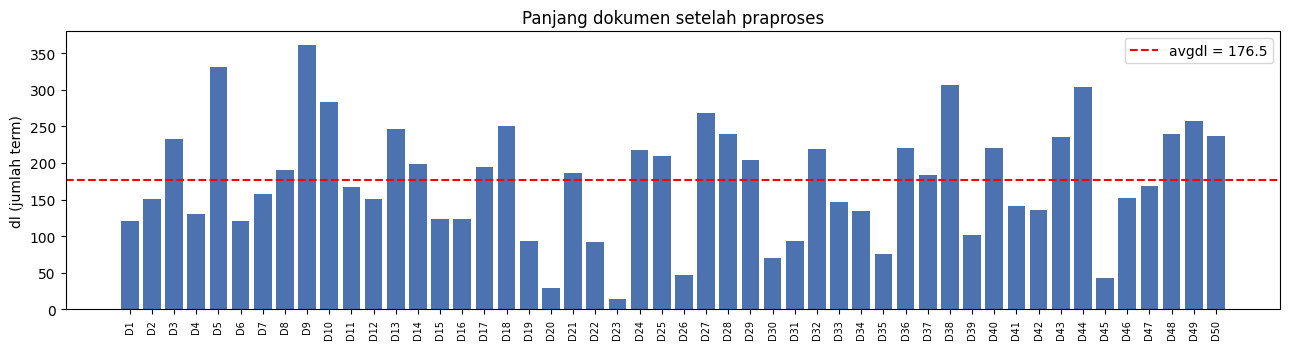

In [4]:
N = len(doc_terms)
ALL_DOCS: List[int] = sorted(doc_terms)
doc_len: Dict[int, int] = {d: len(t) for d, t in doc_terms.items()}      # dl
avgdl: float = sum(doc_len.values()) / N                                  # rata-rata panjang dokumen
tf_doc: Dict[int, Counter] = {d: Counter(t) for d, t in doc_terms.items()}  # tf(t, d)

df_t: Counter = Counter()                                                 # df(t)
for c in tf_doc.values():
    df_t.update(c.keys())

lens = np.array(list(doc_len.values()))
print(f"Jumlah dokumen (N)        : {N}")
print(f"Ukuran vocabulary         : {len(df_t)} term unik")
print(f"Total token               : {lens.sum()}")
print(f"Panjang dok min/avg/maks  : {lens.min()} / {avgdl:.2f} / {lens.max()}")
print(f"Dokumen terpendek         : D{min(doc_len, key=doc_len.get)} ({min(doc_len.values())} term)")
print(f"Dokumen terpanjang        : D{max(doc_len, key=doc_len.get)} ({max(doc_len.values())} term)")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar([f"D{d}" for d in ALL_DOCS], [doc_len[d] for d in ALL_DOCS], color="#4C72B0")
ax.axhline(avgdl, color="red", ls="--", label=f"avgdl = {avgdl:.1f}")
ax.set_ylabel("dl (jumlah term)"); ax.set_title("Panjang dokumen setelah praproses")
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.legend()
plt.tight_layout(); plt.savefig("fig_panjang_dokumen.png", dpi=150); plt.show()

## 5. Model 1: Cosine TF-IDF (skema ltc.ltc), Baseline dari Pertemuan 4
Model ini saya bangun mengikuti praktikum Pertemuan 4: inverted index yang postings-nya menyimpan `(docID, bobot)`, dengan panjang vektor tiap dokumen dihitung sekali saat indexing.

Skema pembobotan **ltc.ltc** (notasi SMART, slide 15 Pertemuan 4):
- **l**: tf logaritmik, `1 + log10(tf)`
- **t**: idf, `log10(N / df)`
- **c**: normalisasi cosine

Bobot term: `w(t, d) = (1 + log10 tf) x log10(N / df)`. Query diperlakukan seperti dokumen pendek dengan skema yang sama. Pencarian memakai pola **term-at-a-time**: hanya postings term query yang ditelusuri, skor diakumulasi per dokumen, lalu dibagi `||q|| x ||d||` sehingga nilainya cosine sebenarnya (0 sampai 1). Top-k diambil dengan `heapq`. Dokumen yang tidak berbagi term dengan query tidak diambil, dan skor yang seri diurutkan menurut docID.

Sebelum dipakai, fungsinya saya validasi dengan korpus contoh dan latihan "banjir surabaya" di slide 8 dan 12. Kalau cocok dengan angka slide, implementasinya bisa dipercaya.

In [5]:
import heapq

def query_terms(query: str) -> Counter:
    """Praproses query dengan pipeline yang sama dengan dokumen; term di luar vocabulary dibuang."""
    return Counter(t for t in preprocess(query) if t in df_t)

def idf_log10(t: str) -> float:
    return math.log10(N / df_t[t])

def bangun_vsm(dt: Dict[int, List[str]]):
    """Index VSM (Pertemuan 4): postings[t] = [(docID, bobot ltc)], idf per term, panjang vektor per dokumen.
    Bobot ltc = (1 + log10 tf) x log10(N / df). Panjang vektor dihitung sekali saat indexing."""
    n = len(dt)
    tfs = {d: Counter(t) for d, t in dt.items()}
    dfs: Counter = Counter()
    for c in tfs.values():
        dfs.update(c.keys())
    idf = {t: math.log10(n / f) for t, f in dfs.items()}
    postings: Dict[str, List[Tuple[int, float]]] = defaultdict(list)
    panjang: Dict[int, float] = {}
    for d in sorted(dt):
        kuadrat = 0.0
        for t, f in tfs[d].items():
            w = (1 + math.log10(f)) * idf[t]
            postings[t].append((d, w))
            kuadrat += w * w
        panjang[d] = math.sqrt(kuadrat)
    return postings, idf, panjang

def cari_vsm(q_terms: List[str], postings, idf, panjang) -> Dict[int, float]:
    """Cosine ltc.ltc dengan akumulator term-at-a-time (pola slide 16 Pertemuan 4).
    Hanya postings term query yang ditelusuri; hasil dibagi panjang dokumen dan panjang query."""
    qc = Counter(t for t in q_terms if t in idf)
    w_q = {t: (1 + math.log10(f)) * idf[t] for t, f in qc.items()}
    pq = math.sqrt(sum(w * w for w in w_q.values()))
    if pq == 0:
        return {}
    skor = defaultdict(float)
    for t, w_tq in w_q.items():
        for d, w_td in postings[t]:
            skor[d] += w_tq * w_td
    return {d: s / (pq * panjang[d]) for d, s in skor.items() if s > 0}

# Validasi dengan korpus contoh Pertemuan 4 (slide 8 dan 12): query "banjir surabaya"
toy = {1: ["banjir", "landa", "surabaya"], 2: ["banjir", "bandang", "terjang", "kota"],
       3: ["surabaya", "kota", "pahlawan"], 4: ["kota", "surabaya", "banjir"]}
p_toy, idf_toy, len_toy = bangun_vsm(toy)
skor_toy = cari_vsm(["banjir", "surabaya"], p_toy, idf_toy, len_toy)
print("Panjang vektor :", {f"D{d}": round(v, 3) for d, v in len_toy.items()}, " (slide: 0,627 / 0,870 / 0,627 / 0,216)")
print("Skor cosine    :", {f"D{d}": round(skor_toy[d], 3) for d in sorted(skor_toy)}, " (slide: D4 0,816 | D1 0,282 | D3 0,141 | D2 0,102)")
assert [round(skor_toy[d], 3) for d in (4, 1, 3, 2)] == [0.816, 0.282, 0.141, 0.102]
print("[OK] Implementasi cosine ltc.ltc cocok dengan latihan di slide 12.")

# Index untuk korpus berita
postings_vsm, idf_vsm, doc_norm = bangun_vsm(doc_terms)      # doc_norm[d] = panjang vektor ||d||

def tfidf_search(query: str) -> Dict[int, float]:
    """Cosine TF-IDF skema ltc.ltc pada korpus berita. Mengembalikan {docID: skor} (skor > 0)."""
    return cari_vsm(preprocess(query), postings_vsm, idf_vsm, doc_norm)

def cari(query: str, k: int = 10):
    """Top-k dengan heap (seperti slide 16), tanpa mengurutkan seluruh dokumen."""
    skor = tfidf_search(query)
    return heapq.nlargest(k, skor.items(), key=lambda x: (x[1], -x[0]))

def ranking(scores: Dict[int, float]) -> List[int]:
    """Urutkan skor menurun; jika seri, docID yang lebih kecil lebih dulu."""
    return sorted(scores, key=lambda d: (-scores[d], d))

def tampilkan_hasil(rank, scores, top=5):
    for i, d in enumerate(rank[:top], 1):
        print(f"  {i}. D{d:<3} skor={scores[d]:.4f}  dl={doc_len[d]:<4} {JUDUL[d][:70]}")

contoh = "presiden Xi Jinping"
print(f"\nQuery: '{contoh}' -> term: {dict(query_terms(contoh))}")
sc = tfidf_search(contoh)
tampilkan_hasil(ranking(sc), sc)
print("Top-3 via heapq:", [(f"D{d}", round(s, 4)) for d, s in cari(contoh, 3)])

Panjang vektor : {'D1': 0.627, 'D2': 0.87, 'D3': 0.627, 'D4': 0.216}  (slide: 0,627 / 0,870 / 0,627 / 0,216)
Skor cosine    : {'D1': 0.282, 'D2': 0.102, 'D3': 0.141, 'D4': 0.816}  (slide: D4 0,816 | D1 0,282 | D3 0,141 | D2 0,102)
[OK] Implementasi cosine ltc.ltc cocok dengan latihan di slide 12.

Query: 'presiden Xi Jinping' -> term: {'presiden': 1, 'xi': 1, 'jinping': 1}
  1. D23  skor=0.6101  dl=14   Presiden China hadiri KTT BRICS di New Delhi, India
  2. D22  skor=0.2228  dl=92   Xi Jinping: China, India saling hadirkan peluang, bukan ancaman
  3. D11  skor=0.1577  dl=167  India-China sepakat selesaikan sengketa perbatasan
  4. D5   skor=0.1537  dl=331  China-India sepakat terus jadi mitra strategis
  5. D9   skor=0.1410  dl=362  Presiden Xi: China siap ambil alih keketuaan BRICS pada 2027
Top-3 via heapq: [('D23', 0.6101), ('D22', 0.2228), ('D11', 0.1577)]


## 6. Model 2: BM25 (k1 = 1,2 dan b = 0,75)
Rumus dari slide Pertemuan 5:

`skor(q, d) = sum over t in q: idf(t) x tf(k1 + 1) / (tf + K)`, dengan `K = k1 x (1 - b + b x dl/avgdl)`

dan `idf(t) = ln(1 + (N - df + 0,5) / (df + 0,5))` (varian Lucene, selalu positif).

Tiap term query unik dihitung sekali dan hanya term yang muncul di dokumen yang menyumbang skor. Sebelum dipakai, saya **validasi** fungsinya dengan angka latihan "banjir surabaya" di slide 10 (N = 4, avgdl = 3,25, df = 3). Kalau cocok dengan perhitungan manual di slide, implementasinya bisa dipercaya.

In [6]:
def idf_bm25(t: str) -> float:
    return math.log(1 + (N - df_t[t] + 0.5) / (df_t[t] + 0.5))

def bm25_term(tf, df_, dl, N_, avgdl_, k1=1.2, b=0.75) -> float:
    """Sumbangan satu term query ke skor BM25 sebuah dokumen (rumus slide 7)."""
    idf = math.log(1 + (N_ - df_ + 0.5) / (df_ + 0.5))
    K = k1 * (1 - b + b * dl / avgdl_)
    return idf * tf * (k1 + 1) / (tf + K)

def bm25_search(query: str, k1: float = 1.2, b: float = 0.75) -> Dict[int, float]:
    """BM25 (idf varian Lucene). Tiap term query unik dihitung sekali."""
    qt = set(query_terms(query))
    scores = {}
    for d in ALL_DOCS:
        s = 0.0
        for t in qt:
            f = tf_doc[d].get(t, 0)
            if f:
                s += bm25_term(f, df_t[t], doc_len[d], N, avgdl, k1, b)
        if s > 0:
            scores[d] = s
    return scores

# Validasi implementasi dengan angka latihan "banjir surabaya" pada slide 10
# (N=4, avgdl=3,25, df=3, k1=1,2, b=0,75)
s_d1 = bm25_term(1, 3, 3, 4, 3.25) * 2          # D1/D4: dua term, tf=1, dl=3
s_d3 = bm25_term(1, 3, 3, 4, 3.25)              # D3: satu term, dl=3
s_d2 = bm25_term(1, 3, 4, 4, 3.25)              # D2: satu term, dl=4
print(f"D1/D4 = {s_d1:.3f} (slide: 0,737) | D3 = {s_d3:.3f} (slide: 0,368) | D2 = {s_d2:.3f} (slide: 0,326)")
assert abs(s_d1 - 0.737) < 0.001 and abs(s_d3 - 0.368) < 0.001 and abs(s_d2 - 0.326) < 0.001
print("[OK] Implementasi BM25 cocok dengan perhitungan manual di slide.")

sc = bm25_search(contoh)
print(f"\nQuery: '{contoh}' (BM25, k1=1,2, b=0,75)")
tampilkan_hasil(ranking(sc), sc)

D1/D4 = 0.737 (slide: 0,737) | D3 = 0.368 (slide: 0,368) | D2 = 0.326 (slide: 0,326)
[OK] Implementasi BM25 cocok dengan perhitungan manual di slide.

Query: 'presiden Xi Jinping' (BM25, k1=1,2, b=0,75)
  1. D9   skor=9.2852  dl=362  Presiden Xi: China siap ambil alih keketuaan BRICS pada 2027
  2. D23  skor=9.2668  dl=14   Presiden China hadiri KTT BRICS di New Delhi, India
  3. D22  skor=8.9979  dl=92   Xi Jinping: China, India saling hadirkan peluang, bukan ancaman
  4. D5   skor=8.6303  dl=331  China-India sepakat terus jadi mitra strategis
  5. D11  skor=7.4834  dl=167  India-China sepakat selesaikan sengketa perbatasan


## 7. Query Uji dan Penilaian Relevansi
Saya menyusun **14 query uji** (syarat minimal 10) dengan variasi: query satu topik sempit (mis. `kapal virgo hilang kontak`), query yang mencakup banyak dokumen (mis. `KTT BRICS New Delhi`), dan query yang kata-katanya umum.

Dokumen relevan saya tentukan **manual** dengan membaca isi artikel. Dokumen dianggap relevan jika membahas topik query secara substansial. Artikel rangkuman berita (D14, D36, D37) dihitung relevan hanya bila topik query menjadi salah satu butir utamanya. Daftar judul dokumen relevan dicetak di bawah supaya penilaiannya mudah dicek ulang.

In [7]:
# Penilaian relevansi manual: dokumen dianggap relevan jika membahas topik query secara substansial
# (artikel rangkuman berita dihitung relevan bila topik query menjadi salah satu butir utamanya).
QUERIES: Dict[str, Tuple[str, Set[int]]] = {
    "Q01": ("kapal virgo hilang kontak",              {1, 24}),
    "Q02": ("pencarian jurnalis hilang selat sunda",  {17, 36, 37}),
    "Q03": ("KTT BRICS New Delhi",                    {5, 9, 11, 14, 16, 22, 23, 27, 30, 31, 32, 34, 41}),
    "Q04": ("hubungan China India",                   {5, 11, 22}),
    "Q05": ("konflik Yaman Houthi Laut Merah",        {19, 35}),
    "Q06": ("Iran Amerika Serikat Selat Hormuz",      {6, 12}),
    "Q07": ("FIFA ASEAN Cup 2026",                    {4, 7}),
    "Q08": ("nilai Pancasila anggota MPR",            {18, 21}),
    "Q09": ("tersangka kebakaran hutan dan lahan",    {25, 49}),
    "Q10": ("kualitas udara Jakarta",                 {40, 46}),
    "Q11": ("tim SAR Basarnas pencarian",             {15, 17, 24, 36, 37}),
    "Q12": ("pemimpin BRICS pernyataan bersama",      {16, 31, 32, 41}),
    "Q13": ("presiden Xi Jinping",                    {5, 9, 11, 22, 23}),
    "Q14": ("museum pembangunan rumah kebudayaan",    {10, 50}),
}

rows = []
for qid, (teks, rel) in QUERIES.items():
    rows.append({"ID": qid, "Query": teks, "Term (setelah praproses)": " ".join(query_terms(teks)),
                 "Jml Relevan": len(rel), "Dokumen Relevan": ", ".join(f"D{d}" for d in sorted(rel))})
display(pd.DataFrame(rows))

print("\nJudul dokumen relevan per query (untuk dicek ulang):")
for qid, (teks, rel) in QUERIES.items():
    print(f"\n{qid} '{teks}'")
    for d in sorted(rel):
        print(f"   D{d:<3} {JUDUL[d][:90]}")

,ID,Query,Term (setelah praproses),Jml Relevan,Dokumen Relevan
0,Q01,kapal virgo hilang kontak,kapal virgo hilang kontak,2,"D1, D24"
1,Q02,pencarian jurnalis hilang selat sunda,cari jurnalis hilang selat sunda,3,"D17, D36, D37"
2,Q03,KTT BRICS New Delhi,ktt brics new delhi,13,"D5, D9, D11, D14, D16, D22, D23, D27, D30, D31, D32, D34, D41"
3,Q04,hubungan China India,hubung china india,3,"D5, D11, D22"
4,Q05,konflik Yaman Houthi Laut Merah,konflik yaman houthi laut merah,2,"D19, D35"
5,Q06,Iran Amerika Serikat Selat Hormuz,iran amerika serikat selat hormuz,2,"D6, D12"
6,Q07,FIFA ASEAN Cup 2026,fifa asean cup,2,"D4, D7"
7,Q08,nilai Pancasila anggota MPR,nilai pancasila anggota mpr,2,"D18, D21"
8,Q09,tersangka kebakaran hutan dan lahan,sangka bakar hutan lahan,2,"D25, D49"
9,Q10,kualitas udara Jakarta,kualitas udara,2,"D40, D46"



Judul dokumen relevan per query (untuk dicek ulang):

Q01 'kapal virgo hilang kontak'
   D1   Polda Kalsel siagakan RS Bhayangkara, siap tangani korban Kapal Virgo
   D24  Kapal Virgo bawa 243 orang hilang kontak di perairan Laut Jawa

Q02 'pencarian jurnalis hilang selat sunda'
   D17  Basarnas fokuskan pencarian jurnalis di perairan selatan GAK
   D36  Kemarin, pencarian jurnalis yang hilang hingga pergeseran harga iPhone
   D37  Sepekan, pencarian jurnalis hilang hingga dentuman keras di Gorontalo

Q03 'KTT BRICS New Delhi'
   D5   China-India sepakat terus jadi mitra strategis
   D9   Presiden Xi: China siap ambil alih keketuaan BRICS pada 2027
   D11  India-China sepakat selesaikan sengketa perbatasan
   D14  Terpopuler, Pertalite-Biosolar tak naik hingga Prabowo di KTT BRICS
   D16  BRICS terima kasih ke Rusia karena adakan pertemuan NDB di Moskow
   D22  Xi Jinping: China, India saling hadirkan peluang, bukan ancaman
   D23  Presiden China hadiri KTT BRICS di New Delhi, India
 

## 8. Menjalankan Kedua Model dan Evaluasi Baseline
Kedua model dijalankan pada seluruh query. Untuk membandingkan, saya pakai tiga ukuran sederhana:
- **AP (Average Precision)** dan **R-Precision**: seberapa tinggi dokumen relevan diletakkan model. P@5 tidak saya pakai karena banyak query hanya punya 2-3 dokumen relevan, sehingga P@5 tidak bisa mencapai 1.
- **Kendall tau**: seberapa mirip urutan TF-IDF dan BM25 (1 = identik, 0 = tak berkorelasi, -1 = berkebalikan).

Kendall tau sengaja saya hitung terpisah dari AP: dua model bisa sama-sama bagus menurut AP tetapi urutan dokumennya berbeda, dan perbedaan urutan itulah yang diminta dianalisis. Metrik evaluasi yang lebih lengkap baru dibahas di Pertemuan 6.

In [8]:
def average_precision(rank: List[int], rel: Set[int]) -> float:
    hit, total = 0, 0.0
    for i, d in enumerate(rank, 1):
        if d in rel:
            hit += 1
            total += hit / i
    return total / len(rel)

def r_precision(rank: List[int], rel: Set[int]) -> float:
    R = len(rel)
    return sum(d in rel for d in rank[:R]) / R

def kendall_tau(rank_a: List[int], rank_b: List[int]) -> float:
    """Korelasi Kendall tau antara dua peringkat pada dokumen yang diambil kedua model."""
    set_b = set(rank_b)
    common = [d for d in rank_a if d in set_b]
    if len(common) < 2:
        return 1.0
    pos_a = {d: i for i, d in enumerate(rank_a)}
    pos_b = {d: i for i, d in enumerate(rank_b)}
    return kendalltau([pos_a[d] for d in common], [pos_b[d] for d in common])[0]

# Jalankan kedua model pada semua query
sc_tfidf = {q: tfidf_search(t) for q, (t, _) in QUERIES.items()}
sc_bm25  = {q: bm25_search(t, 1.2, 0.75) for q, (t, _) in QUERIES.items()}
rk_tfidf = {q: ranking(s) for q, s in sc_tfidf.items()}
rk_bm25  = {q: ranking(s) for q, s in sc_bm25.items()}

rows = []
for qid, (teks, rel) in QUERIES.items():
    a, b_ = rk_tfidf[qid], rk_bm25[qid]
    rows.append({
        "ID": qid, "Query": teks, "Jml dok terambil": f"{len(a)} / {len(b_)}",
        "AP TF-IDF": average_precision(a, rel), "AP BM25": average_precision(b_, rel),
        "R-Prec TF-IDF": r_precision(a, rel), "R-Prec BM25": r_precision(b_, rel),
        "Kendall tau": kendall_tau(a, b_),
        "Top-1 sama?": "Ya" if a[0] == b_[0] else f"Tidak (D{a[0]} vs D{b_[0]})",
        "Urutan top-5 identik?": "Ya" if a[:5] == b_[:5] else "Tidak",
    })
hasil_baseline = pd.DataFrame(rows)
display(hasil_baseline.round(3))

print(f"MAP  TF-IDF : {hasil_baseline['AP TF-IDF'].mean():.4f}   |   MAP  BM25 : {hasil_baseline['AP BM25'].mean():.4f}")
print(f"R-Prec TF-IDF: {hasil_baseline['R-Prec TF-IDF'].mean():.4f}   |   R-Prec BM25: {hasil_baseline['R-Prec BM25'].mean():.4f}")
print(f"Rata-rata Kendall tau: {hasil_baseline['Kendall tau'].mean():.3f}")
print(f"Query dengan top-5 berbeda: {(hasil_baseline['Urutan top-5 identik?'] == 'Tidak').sum()} dari {len(QUERIES)}")

,ID,Query,Jml dok terambil,AP TF-IDF,AP BM25,R-Prec TF-IDF,R-Prec BM25,Kendall tau,Top-1 sama?,Urutan top-5 identik?
0,Q01,kapal virgo hilang kontak,9 / 9,1.000,1.000,1.000,1.0,0.833,Tidak (D1 vs D24),Tidak
1,Q02,pencarian jurnalis hilang selat sunda,14 / 14,1.000,1.000,1.000,1.0,0.890,Ya,Tidak
2,Q03,KTT BRICS New Delhi,14 / 14,1.000,1.000,1.000,1.0,0.802,Tidak (D23 vs D16),Tidak
3,Q04,hubungan China India,18 / 18,0.533,1.000,0.333,1.0,0.791,Tidak (D23 vs D5),Tidak
4,Q05,konflik Yaman Houthi Laut Merah,15 / 15,1.000,1.000,1.000,1.0,0.829,Ya,Tidak
5,Q06,Iran Amerika Serikat Selat Hormuz,13 / 13,1.000,1.000,1.000,1.0,0.897,Ya,Tidak
6,Q07,FIFA ASEAN Cup 2026,2 / 2,1.000,1.000,1.000,1.0,-1.000,Tidak (D4 vs D7),Tidak
7,Q08,nilai Pancasila anggota MPR,20 / 20,1.000,1.000,1.000,1.0,0.874,Ya,Ya
8,Q09,tersangka kebakaran hutan dan lahan,9 / 9,1.000,1.000,1.000,1.0,0.833,Ya,Tidak
9,Q10,kualitas udara Jakarta,9 / 9,0.750,1.000,0.500,1.0,0.778,Ya,Tidak


MAP  TF-IDF : 0.9355   |   MAP  BM25 : 0.9948
R-Prec TF-IDF: 0.8845   |   R-Prec BM25: 0.9857
Rata-rata Kendall tau: 0.679
Query dengan top-5 berbeda: 13 dari 14


## 9. Query yang Peringkatnya Berbeda
Pada bab ini saya menampilkan tabel peringkat kedua model berdampingan untuk query yang paling layak dianalisis. Kriterianya: selisih AP terbesar, lalu Kendall tau terkecil. Query yang hanya mengambil kurang dari 5 dokumen (mis. Q07, hanya 2 dokumen) dilewati karena korelasi peringkat pada 2-3 dokumen tidak bermakna. Kolom **Selisih** = peringkat TF-IDF dikurangi peringkat BM25. Selisih positif artinya BM25 menaikkan dokumen itu, negatif artinya BM25 menurunkannya.

In [9]:
def tabel_peringkat(qid: str, top: int = 10) -> pd.DataFrame:
    teks, rel = QUERIES[qid]
    a, b_ = rk_tfidf[qid], rk_bm25[qid]
    pos_a = {d: i + 1 for i, d in enumerate(a)}
    pos_b = {d: i + 1 for i, d in enumerate(b_)}
    kandidat = sorted(set(a[:top]) | set(b_[:top]), key=lambda d: min(pos_a[d], pos_b[d]))
    rows = [{"Dok": f"D{d}", "dl": doc_len[d],
             "Peringkat TF-IDF": pos_a[d], "Skor TF-IDF": round(sc_tfidf[qid][d], 4),
             "Peringkat BM25": pos_b[d], "Skor BM25": round(sc_bm25[qid][d], 4),
             "Selisih": pos_a[d] - pos_b[d], "Relevan": "v" if d in rel else ""}
            for d in kandidat]
    return pd.DataFrame(rows)

# Pilih query yang paling layak dianalisis: selisih AP terbesar, lalu Kendall tau terkecil.
# Query yang hanya mengambil < 5 dokumen dilewati (korelasi peringkat pada 2-3 dokumen tidak bermakna).
kandidat = hasil_baseline[hasil_baseline["ID"].map(lambda q: len(rk_bm25[q])) >= 5].copy()
kandidat["Selisih AP"] = (kandidat["AP BM25"] - kandidat["AP TF-IDF"]).abs()
paling_beda = kandidat.sort_values(["Selisih AP", "Kendall tau"], ascending=[False, True]).head(4)["ID"].tolist()
print("Query yang dianalisis lebih lanjut:", paling_beda)
for qid in paling_beda:
    tau = hasil_baseline.loc[hasil_baseline["ID"] == qid, "Kendall tau"].iloc[0]
    print(f"\n{qid} '{QUERIES[qid][0]}'  (Kendall tau = {tau:.3f}; Selisih = peringkat TF-IDF - peringkat BM25)")
    display(tabel_peringkat(qid))

Query yang dianalisis lebih lanjut: ['Q04', 'Q10', 'Q12', 'Q13']

Q04 'hubungan China India'  (Kendall tau = 0.791; Selisih = peringkat TF-IDF - peringkat BM25)


,Dok,dl,Peringkat TF-IDF,Skor TF-IDF,Peringkat BM25,Skor BM25,Selisih,Relevan
0,D5,331,5,0.1586,1,8.8727,4,v
1,D23,14,1,0.3079,5,4.8281,-4,
2,D22,92,2,0.2109,2,8.3224,0,v
3,D11,167,4,0.1596,3,7.8344,1,v
4,D16,124,3,0.1647,4,6.9911,-1,
5,D31,93,6,0.0941,8,4.1917,-2,
6,D34,134,7,0.0831,6,4.2911,1,
7,D9,362,9,0.0658,7,4.2400,2,
8,D41,141,8,0.0722,10,3.7681,-2,
9,D36,221,10,0.0626,9,3.9379,1,



Q10 'kualitas udara Jakarta'  (Kendall tau = 0.778; Selisih = peringkat TF-IDF - peringkat BM25)


,Dok,dl,Peringkat TF-IDF,Skor TF-IDF,Peringkat BM25,Skor BM25,Selisih,Relevan
0,D46,152,1,0.2165,1,8.9268,0,v
1,D40,221,4,0.0712,2,3.8116,2,v
2,D20,29,2,0.1282,3,3.3839,-1,
3,D35,75,3,0.0728,5,2.9120,-2,
4,D37,183,5,0.0634,4,3.0306,1,
5,D17,194,6,0.0453,6,2.1401,0,
6,D5,331,7,0.0440,8,1.6396,-1,
7,D28,239,8,0.0424,7,1.9451,1,
8,D9,362,9,0.0373,9,1.5572,0,



Q12 'pemimpin BRICS pernyataan bersama'  (Kendall tau = 0.683; Selisih = peringkat TF-IDF - peringkat BM25)


,Dok,dl,Peringkat TF-IDF,Skor TF-IDF,Peringkat BM25,Skor BM25,Selisih,Relevan
0,D41,141,1,0.1870,1,9.0420,0,v
1,D31,93,2,0.1865,2,7.8887,0,v
2,D32,219,5,0.1016,3,6.1011,2,v
3,D35,75,3,0.1118,5,4.8596,-2,
4,D16,124,4,0.1043,4,5.2081,0,v
5,D23,14,6,0.0937,15,2.0176,-9,
6,D34,134,8,0.0722,6,4.4176,2,
7,D11,167,10,0.0685,7,4.3000,3,
8,D27,269,7,0.0742,8,4.2042,-1,
9,D22,92,9,0.0709,9,3.8504,0,



Q13 'presiden Xi Jinping'  (Kendall tau = 0.727; Selisih = peringkat TF-IDF - peringkat BM25)


,Dok,dl,Peringkat TF-IDF,Skor TF-IDF,Peringkat BM25,Skor BM25,Selisih,Relevan
0,D9,362,5,0.1410,1,9.2852,4,v
1,D23,14,1,0.6101,2,9.2668,-1,v
2,D22,92,2,0.2228,3,8.9979,-1,v
3,D11,167,3,0.1577,5,7.4834,-2,v
4,D5,331,4,0.1537,4,8.6303,0,v
5,D41,141,6,0.0477,6,2.2445,0,
6,D30,70,7,0.0347,10,1.9776,-3,
7,D34,134,8,0.0337,7,2.1967,1,
8,D27,269,10,0.0257,8,2.1042,2,
9,D37,183,9,0.0257,9,2.0269,0,


## 10. Uji Pengaruh Parameter k1 dan b
BM25 saya ulang untuk **4 nilai k1** (0,5; 1,2; 2,0; 3,0) dan **5 nilai b** (0; 0,25; 0,5; 0,75; 1), jadi 20 kombinasi. Untuk tiap kombinasi saya catat:
- MAP dan R-Precision (kualitas),
- Kendall tau terhadap baseline k1 = 1,2 dan b = 0,75 (seberapa jauh urutan bergeser),
- jumlah query yang top-1 dan top-5-nya berubah.

Selanjutnya fungsi `lacak_peringkat` menunjukkan **dokumen mana** yang naik atau turun ketika satu parameter diubah, dan grafik di bawahnya membandingkan bentuk fungsi saturasi tf BM25 dengan `1 + log10(tf)` dari Pertemuan 4 serta efek b terhadap dokumen panjang.

Pengaruh k1 dan b terhadap kualitas dan perubahan peringkat (baseline: k1=1,2; b=0,75)


,k1,b,MAP,R-Prec,tau vs baseline,Query top-1 berubah,Query top-5 berubah
0,0.5,0.00,0.9912,0.9679,0.7629,1,8
1,0.5,0.25,0.9888,0.9679,0.8789,0,6
2,0.5,0.50,0.9912,0.9679,0.9153,0,6
3,0.5,0.75,0.9912,0.9679,0.9623,1,4
4,0.5,1.00,0.9793,0.9321,0.7866,4,7
5,1.2,0.00,0.9948,0.9857,0.7677,1,7
6,1.2,0.25,0.9948,0.9857,0.8996,0,6
7,1.2,0.50,0.9948,0.9857,0.9444,0,5
8,1.2,0.75,0.9948,0.9857,1.0000,0,0
9,1.2,1.00,0.9793,0.9321,0.8031,4,8


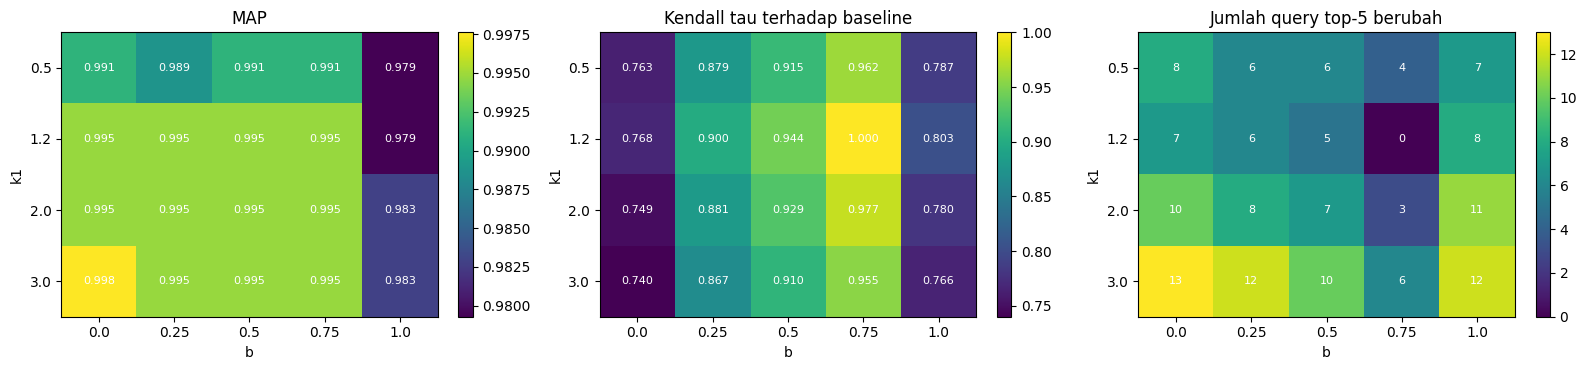

In [10]:
K1_LIST = [0.5, 1.2, 2.0, 3.0]
B_LIST  = [0.0, 0.25, 0.5, 0.75, 1.0]
base_rank = {q: rk_bm25[q] for q in QUERIES}          # acuan: k1 = 1,2 dan b = 0,75

grid_rows = []
for k1 in K1_LIST:
    for b in B_LIST:
        aps, rps, taus, top1_ch, top5_ch = [], [], [], 0, 0
        for qid, (teks, rel) in QUERIES.items():
            rk = ranking(bm25_search(teks, k1, b))
            aps.append(average_precision(rk, rel)); rps.append(r_precision(rk, rel))
            taus.append(kendall_tau(base_rank[qid], rk))
            top1_ch += int(rk[0] != base_rank[qid][0])
            top5_ch += int(rk[:5] != base_rank[qid][:5])
        grid_rows.append({"k1": k1, "b": b, "MAP": np.mean(aps), "R-Prec": np.mean(rps),
                          "tau vs baseline": np.mean(taus), "Query top-1 berubah": top1_ch,
                          "Query top-5 berubah": top5_ch})
df_grid = pd.DataFrame(grid_rows)
print("Pengaruh k1 dan b terhadap kualitas dan perubahan peringkat (baseline: k1=1,2; b=0,75)")
display(df_grid.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, kolom, judul in zip(axes, ["MAP", "tau vs baseline", "Query top-5 berubah"],
                            ["MAP", "Kendall tau terhadap baseline", "Jumlah query top-5 berubah"]):
    pv = df_grid.pivot(index="k1", columns="b", values=kolom)
    im = ax.imshow(pv.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
    ax.set_yticks(range(len(pv.index)));   ax.set_yticklabels(pv.index)
    ax.set_xlabel("b"); ax.set_ylabel("k1"); ax.set_title(judul)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f"{pv.values[i, j]:.3f}" if kolom != "Query top-5 berubah" else f"{int(pv.values[i, j])}",
                    ha="center", va="center", color="white", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig("fig_grid_parameter.png", dpi=150); plt.show()


Q04 'hubungan China India' - mengubah b (k1 = 1,2)


,Dok,dl,Relevan,"k1=1.2, b=0.0","k1=1.2, b=0.25","k1=1.2, b=0.5","k1=1.2, b=0.75","k1=1.2, b=1.0"
0,D5,331,v,1,1,1,1,1
1,D22,92,v,3,2,2,2,2
2,D11,167,v,2,3,3,3,3
3,D16,124,,4,4,4,4,4
4,D23,14,,10,10,8,5,5
5,D34,134,,7,7,6,6,7
6,D9,362,,5,5,5,7,8
7,D31,93,,8,8,9,8,6


Q04 - mengubah k1 (b = 0,75)


,Dok,dl,Relevan,"k1=0.5, b=0.75","k1=1.2, b=0.75","k1=2.0, b=0.75","k1=3.0, b=0.75"
0,D5,331,v,1,1,1,1
1,D22,92,v,2,2,2,2
2,D11,167,v,3,3,3,3
3,D16,124,,4,4,4,4
4,D23,14,,5,5,5,5
5,D34,134,,7,6,6,7
6,D9,362,,8,7,7,6
7,D31,93,,6,8,8,8



Q12 'pemimpin BRICS pernyataan bersama' - mengubah b (k1 = 1,2)


,Dok,dl,Relevan,"k1=1.2, b=0.0","k1=1.2, b=0.25","k1=1.2, b=0.5","k1=1.2, b=0.75","k1=1.2, b=1.0"
0,D41,141,v,1,1,1,1,1
1,D31,93,v,2,2,2,2,2
2,D32,219,v,3,3,3,3,3
3,D16,124,v,4,4,4,4,5
4,D35,75,,10,8,5,5,4
5,D34,134,,8,7,7,6,6
6,D11,167,,6,6,8,7,7
7,D27,269,,5,5,6,8,9


Q12 - mengubah k1 (b = 0,75)


,Dok,dl,Relevan,"k1=0.5, b=0.75","k1=1.2, b=0.75","k1=2.0, b=0.75","k1=3.0, b=0.75"
0,D41,141,v,1,1,1,1
1,D31,93,v,2,2,2,2
2,D32,219,v,3,3,3,4
3,D16,124,v,5,4,4,3
4,D35,75,,4,5,5,7
5,D34,134,,7,6,6,5
6,D11,167,,8,7,7,6
7,D27,269,,6,8,8,8


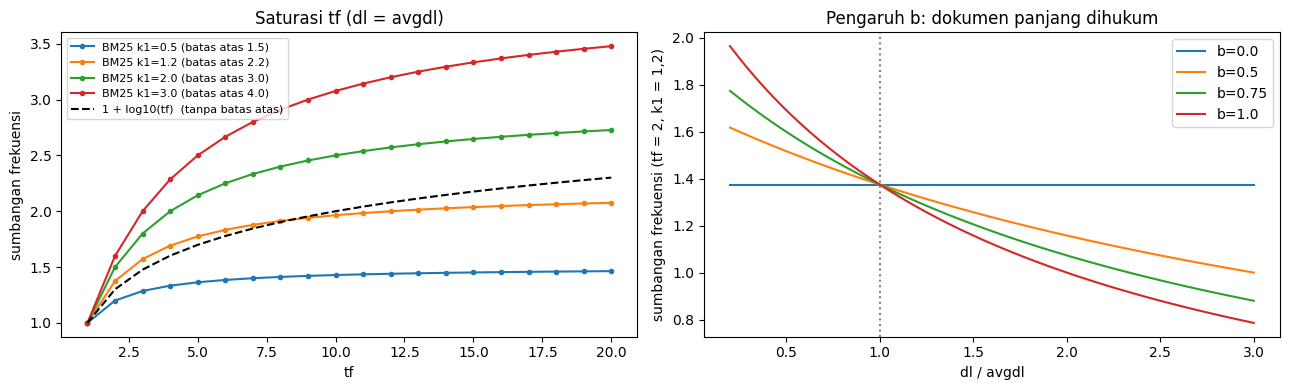

In [11]:
def lacak_peringkat(qid: str, konfigurasi: List[Tuple[float, float]], top: int = 8) -> pd.DataFrame:
    """Peringkat dokumen-dokumen teratas baseline pada berbagai kombinasi (k1, b)."""
    teks, rel = QUERIES[qid]
    docs = base_rank[qid][:top]
    tabel = {"Dok": [f"D{d}" for d in docs], "dl": [doc_len[d] for d in docs],
             "Relevan": ["v" if d in rel else "" for d in docs]}
    for (k1, b) in konfigurasi:
        rk = ranking(bm25_search(teks, k1, b))
        tabel[f"k1={k1}, b={b}"] = [rk.index(d) + 1 for d in docs]
    return pd.DataFrame(tabel)

for qid in ["Q04", "Q12"]:
    print(f"\n{qid} '{QUERIES[qid][0]}' - mengubah b (k1 = 1,2)")
    display(lacak_peringkat(qid, [(1.2, b) for b in B_LIST]))
    print(f"{qid} - mengubah k1 (b = 0,75)")
    display(lacak_peringkat(qid, [(k1, 0.75) for k1 in K1_LIST]))

# Visualisasi bentuk fungsi (membuktikan klaim slide 8 dan 9)
tf_range = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k1 in [0.5, 1.2, 2.0, 3.0]:
    axes[0].plot(tf_range, tf_range * (k1 + 1) / (tf_range + k1), marker="o", ms=3, label=f"BM25 k1={k1} (batas atas {k1 + 1})")
axes[0].plot(tf_range, 1 + np.log10(tf_range), "k--", label="1 + log10(tf)  (tanpa batas atas)")
axes[0].set_xlabel("tf"); axes[0].set_ylabel("sumbangan frekuensi"); axes[0].set_title("Saturasi tf (dl = avgdl)"); axes[0].legend(fontsize=8)

rasio = np.linspace(0.2, 3, 60)       # dl / avgdl
for b in [0.0, 0.5, 0.75, 1.0]:
    K = 1.2 * (1 - b + b * rasio)
    axes[1].plot(rasio, 2 * (1.2 + 1) / (2 + K), label=f"b={b}")
axes[1].axvline(1, color="gray", ls=":")
axes[1].set_xlabel("dl / avgdl"); axes[1].set_ylabel("sumbangan frekuensi (tf = 2, k1 = 1,2)")
axes[1].set_title("Pengaruh b: dokumen panjang dihukum"); axes[1].legend()
plt.tight_layout(); plt.savefig("fig_bentuk_fungsi.png", dpi=150); plt.show()

## 11. Analisis Penyebab Perbedaan Peringkat (Berdasarkan Rumus)
Tugas meminta penjelasan **berdasarkan rumus, bukan sekadar angka**, jadi saya membuat fungsi `jelaskan(query, docID)` yang membongkar skor satu dokumen per term:

- **Sisi cosine**: `tf`, `idf10`, bobot ltc mentah `w ltc`, bobot setelah dibagi panjang vektor `w/|d|`, dan `kontribusi cosine`.
- **Sisi BM25**: `idf BM25`, komponen saturasi `tf-sat = tf(k1+1)/(tf+K)`, dan `kontribusi BM25`.
- Baris ringkasan: `dl`, `dl/avgdl`, `K`, panjang vektor `|d|`, dan total skor kedua model.

`pasangan_kasus` memilih dokumen yang dibandingkan secara otomatis. Prioritasnya pasangan (non-relevan, relevan) yang urutannya terbalik antara dua model. Kalau tidak ada, dipakai top-1 TF-IDF vs top-1 BM25. Dari rincian ini terlihat apakah selisih peringkat berasal dari normalisasi panjang (`|d|` vs `K`), saturasi tf, atau idf.

In [12]:
def jelaskan(qtext: str, d: int, k1: float = 1.2, b: float = 0.75) -> pd.DataFrame:
    """Rincian sumbangan tiap term query pada skor TF-IDF (cosine) dan BM25 untuk satu dokumen."""
    qc = query_terms(qtext)
    qw = {t: (1 + math.log10(f)) * idf_log10(t) for t, f in qc.items()}
    qn = math.sqrt(sum(v * v for v in qw.values()))
    K = k1 * (1 - b + b * doc_len[d] / avgdl)
    rows = []
    for t in qc:
        f = tf_doc[d].get(t, 0)
        w_raw = (1 + math.log10(f)) * idf_log10(t) if f else 0.0
        w_cos = w_raw / doc_norm[d]
        kontrib_cos = (qw[t] / qn) * w_cos
        kontrib_bm = idf_bm25(t) * f * (k1 + 1) / (f + K) if f else 0.0
        rows.append({"term": t, "tf": f, "df": df_t[t], "idf10": round(idf_log10(t), 3),
                     "w ltc": round(w_raw, 3), "w/|d|": round(w_cos, 4), "kontribusi cosine": round(kontrib_cos, 4),
                     "idf BM25": round(idf_bm25(t), 3), "tf-sat": round(f * (k1 + 1) / (f + K), 3) if f else 0.0,
                     "kontribusi BM25": round(kontrib_bm, 4)})
    out = pd.DataFrame(rows)
    ringkas = (f"D{d}: dl={doc_len[d]} (dl/avgdl={doc_len[d] / avgdl:.2f}), K={K:.3f}, "
               f"panjang vektor |d|={doc_norm[d]:.3f}, term unik={len(tf_doc[d])} | "
               f"cosine={out['kontribusi cosine'].sum():.4f}, BM25={out['kontribusi BM25'].sum():.4f}")
    print(ringkas)
    return out

def pasangan_kasus(qid: str):
    """Pilih pasangan dokumen yang paling layak dibandingkan:
    1) pasangan (non-relevan, relevan) yang urutannya terbalik antara dua model;
    2) jika tidak ada, top-1 TF-IDF vs top-1 BM25;
    3) jika top-1 sama, dokumen dengan pergeseran peringkat terbesar vs top-1."""
    rel = QUERIES[qid][1]
    a, b_ = rk_tfidf[qid], rk_bm25[qid]
    pos_a = {d: i + 1 for i, d in enumerate(a)}
    pos_b = {d: i + 1 for i, d in enumerate(b_)}
    terbalik = [(n, r) for n in a if n not in rel for r in rel if r in pos_a
                and (pos_a[n] < pos_a[r]) != (pos_b[n] < pos_b[r])]
    if terbalik:
        n, r = min(terbalik, key=lambda p: min(pos_a[p[0]], pos_b[p[0]]) + min(pos_a[p[1]], pos_b[p[1]]))
        return n, r
    if a[0] != b_[0]:
        return a[0], b_[0]
    geser = max(a, key=lambda d: abs(pos_a[d] - pos_b[d]))
    return geser, a[0]

for qid in paling_beda:
    teks = QUERIES[qid][0]
    d_a, d_b = pasangan_kasus(qid)
    print(f"\n{'=' * 110}\n{qid} '{teks}'  ->  membandingkan D{d_a} dan D{d_b}")
    for d in (d_a, d_b):
        print(f"\n[{JUDUL[d][:80]}]  relevan: {'ya' if d in QUERIES[qid][1] else 'tidak'}")
        display(jelaskan(teks, d))
    print(f"Peringkat TF-IDF: D{d_a}=#{rk_tfidf[qid].index(d_a) + 1}, D{d_b}=#{rk_tfidf[qid].index(d_b) + 1} | "
          f"Peringkat BM25: D{d_a}=#{rk_bm25[qid].index(d_a) + 1}, D{d_b}=#{rk_bm25[qid].index(d_b) + 1}")

# Kasus tambahan: dokumen sangat pendek (D23, hanya 1 kalimat) pada query BRICS umum
print(f"\n{'=' * 110}\nKasus tambahan: dokumen terpendek pada Q12 (D23, dl={doc_len[23]})")
display(jelaskan(QUERIES["Q12"][0], 23))
print(f"Peringkat D23 pada Q12 -> TF-IDF: #{rk_tfidf['Q12'].index(23) + 1} | BM25: #{rk_bm25['Q12'].index(23) + 1}")


Q04 'hubungan China India'  ->  membandingkan D23 dan D5

[Presiden China hadiri KTT BRICS di New Delhi, India]  relevan: tidak
D23: dl=14 (dl/avgdl=0.08), K=0.371, panjang vektor |d|=2.475, term unik=12 | cosine=0.3079, BM25=4.8281


,term,tf,df,idf10,w ltc,w/|d|,kontribusi cosine,idf BM25,tf-sat,kontribusi BM25
0,hubung,0,10,0.699,0.000,0.0000,0.0000,1.580,0.000,0.0000
1,china,1,9,0.745,0.745,0.3009,0.1904,1.681,1.604,2.6959
2,india,1,13,0.585,0.585,0.2364,0.1175,1.329,1.604,2.1322



[China-India sepakat terus jadi mitra strategis]  relevan: ya
D5: dl=331 (dl/avgdl=1.88), K=1.988, panjang vektor |d|=16.063, term unik=161 | cosine=0.1586, BM25=8.8727


,term,tf,df,idf10,w ltc,w/|d|,kontribusi cosine,idf BM25,tf-sat,kontribusi BM25
0,hubung,11,10,0.699,1.427,0.0888,0.0528,1.580,1.863,2.9447
1,china,17,9,0.745,1.661,0.1034,0.0654,1.681,1.970,3.3101
2,india,17,13,0.585,1.305,0.0812,0.0404,1.329,1.970,2.6179


Peringkat TF-IDF: D23=#1, D5=#5 | Peringkat BM25: D23=#5, D5=#1

Q10 'kualitas udara Jakarta'  ->  membandingkan D20 dan D40

[Bersama memajukan pembangunan dan kerja sama BRICS yang lebih luas]  relevan: tidak
D20: dl=29 (dl/avgdl=0.16), K=0.448, panjang vektor |d|=5.514, term unik=23 | cosine=0.1282, BM25=3.3839


...


[Presiden Xi: China siap ambil alih keketuaan BRICS pada 2027]  relevan: ya
D9: dl=362 (dl/avgdl=2.05), K=2.146, panjang vektor |d|=18.968, term unik=221 | cosine=0.1410, BM25=9.2852


,term,tf,df,idf10,w ltc,w/|d|,kontribusi cosine,idf BM25,tf-sat,kontribusi BM25
0,presiden,10,11,0.658,1.315,0.0693,0.0302,1.489,1.811,2.6978
1,xi,10,6,0.921,1.842,0.0971,0.0592,2.060,1.811,3.7312
2,jinping,3,5,1.000,1.477,0.0779,0.0516,2.227,1.282,2.8562


Peringkat TF-IDF: D23=#1, D9=#5 | Peringkat BM25: D23=#2, D9=#1

Kasus tambahan: dokumen terpendek pada Q12 (D23, dl=14)
D23: dl=14 (dl/avgdl=0.08), K=0.371, panjang vektor |d|=2.475, term unik=12 | cosine=0.0937, BM25=2.0176


,term,tf,df,idf10,w ltc,w/|d|,kontribusi cosine,idf BM25,tf-sat,kontribusi BM25
0,pimpin,0,11,0.658,0.000,0.0000,0.0000,1.489,0.000,0.0000
1,brics,1,14,0.553,0.553,0.2234,0.0937,1.258,1.604,2.0176
2,nyata,0,5,1.000,0.000,0.0000,0.0000,2.227,0.000,0.0000


Peringkat D23 pada Q12 -> TF-IDF: #6 | BM25: #15


## 12. Menyimpan Hasil untuk Laporan
Semua tabel dan grafik disimpan ke file supaya bisa dipakai di laporan dan ikut diunggah ke repositori kode.

In [13]:
rows = []
for qid, (teks, rel) in QUERIES.items():
    pos_a = {d: i + 1 for i, d in enumerate(rk_tfidf[qid])}
    pos_b = {d: i + 1 for i, d in enumerate(rk_bm25[qid])}
    for d in rk_tfidf[qid]:
        rows.append({"query_id": qid, "query": teks, "docID": d, "dl": doc_len[d],
                     "rank_tfidf": pos_a[d], "skor_tfidf": sc_tfidf[qid][d],
                     "rank_bm25": pos_b[d], "skor_bm25": sc_bm25[qid][d], "relevan": int(d in rel)})
pd.DataFrame(rows).to_csv("hasil_ranking_tfidf_vs_bm25.csv", index=False)
hasil_baseline.to_csv("hasil_evaluasi_baseline.csv", index=False)
df_grid.to_csv("hasil_grid_k1_b.csv", index=False)
print("Tersimpan: hasil_ranking_tfidf_vs_bm25.csv, hasil_evaluasi_baseline.csv, hasil_grid_k1_b.csv")
print("Gambar   : fig_panjang_dokumen.png, fig_grid_parameter.png, fig_bentuk_fungsi.png")

Tersimpan: hasil_ranking_tfidf_vs_bm25.csv, hasil_evaluasi_baseline.csv, hasil_grid_k1_b.csv
Gambar   : fig_panjang_dokumen.png, fig_grid_parameter.png, fig_bentuk_fungsi.png


In [14]:
import zipfile, shutil, os
from google.colab import files, drive

berkas = ["berita_indonesia_50.csv",
          "hasil_ranking_tfidf_vs_bm25.csv", "hasil_evaluasi_baseline.csv", "hasil_grid_k1_b.csv",
          "fig_panjang_dokumen.png", "fig_grid_parameter.png", "fig_bentuk_fungsi.png"]

# 1) Unduh semua sekaligus ke laptop
with zipfile.ZipFile("hasil_tugas_mandiri_1.zip", "w") as z:
    for f in berkas:
        z.write(f)
files.download("hasil_tugas_mandiri_1.zip")

# 2) Salinan cadangan di Google Drive (folder Tugas_IR)
drive.mount("/content/drive")
tujuan = "/content/drive/MyDrive/Tugas_IR"
os.makedirs(tujuan, exist_ok=True)
for f in berkas:
    shutil.copy(f, tujuan)
print("Tersalin ke Drive:", tujuan)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mounted at /content/drive
Tersalin ke Drive: /content/drive/MyDrive/Tugas_IR
